<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Neural_Networks_for_Image_Classification1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIG788 - Task 7C: Neural Networks for Image Classification

**Student:** Bylhah Mugotitsa
**Dataset:** Fashion-MNIST
**Dataset source:** https://www.kaggle.com/datasets/zalando-research/fashionmnist
**Model API:** `sklearn.neural_network` (https://scikit-learn.org/stable/api/sklearn.neural_network.html)

This notebook works through five required sections:

1. Understanding the Dataset and Developing a Baseline Neural Network
2. Investigating the Effect of Network Depth
3. Investigating the Effect of Network Width
4. Comparing the Effects of Depth and Width
5. Hyperparameter Tuning, Error Analysis, and Model Recommendation



In [1]:
# -- Install packages -------------
import importlib
import subprocess
import sys

required_packages = {
    'sklearn': 'scikit-learn',
    'pandas': 'pandas',
    'numpy': 'numpy',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn'
}

missing = [pip_name for module_name, pip_name in required_packages.items()
           if importlib.util.find_spec(module_name) is None]

if missing:
    print('Installing missing packages:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
    importlib.invalidate_caches()
    print('Done. No kernel restart needed, continue running the remaining cells in order below.')
else:
    print('All required packages are already installed.')

All required packages are already installed.


In [2]:
# -- Import required libraries -------------------------------------------------
import gzip
import io
import os
import time
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
RANDOM_STATE = 42

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print('Libraries loaded successfully.')

Libraries loaded successfully.


---
# 1. Understanding the Dataset and Developing a Baseline Neural Network
---

Fashion-MNIST [1] is a drop-in replacement for the original MNIST digit dataset, consisting of 28x28 grayscale images of 10 clothing categories, released by Zalando Research specifically because the original MNIST digits had become too easy for modern models to be a useful benchmark. The dataset is available on Kaggle [2].


In [3]:
# -- Load Fashion-MNIST directly --------
CACHE_FILES = {
    'Xtr': 'fmnist_Xtr.npy', 'ytr': 'fmnist_ytr.npy',
    'Xte': 'fmnist_Xte.npy', 'yte': 'fmnist_yte.npy'
}

def load_idx_images(data):
    with gzip.GzipFile(fileobj=io.BytesIO(data)) as f:
        _, n, rows, cols = np.frombuffer(f.read(16), dtype='>i4')
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows * cols)

def load_idx_labels(data):
    with gzip.GzipFile(fileobj=io.BytesIO(data)) as f:
        _, n = np.frombuffer(f.read(8), dtype='>i4')
        return np.frombuffer(f.read(), dtype=np.uint8)

if all(os.path.exists(p) for p in CACHE_FILES.values()):
    print('Using local cached Fashion-MNIST files.')
    X_train_full = np.load(CACHE_FILES['Xtr'])
    y_train_full = np.load(CACHE_FILES['ytr'])
    X_test_full = np.load(CACHE_FILES['Xte'])
    y_test_full = np.load(CACHE_FILES['yte'])
else:
    base_url = 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
    print(f'Local cache not found - downloading from {base_url} ...')

    def fetch(name):
        req = urllib.request.Request(base_url + name, headers={'User-Agent': 'Mozilla/5.0'})
        return urllib.request.urlopen(req, timeout=60).read()

    X_train_full = load_idx_images(fetch('train-images-idx3-ubyte.gz'))
    y_train_full = load_idx_labels(fetch('train-labels-idx1-ubyte.gz'))
    X_test_full = load_idx_images(fetch('t10k-images-idx3-ubyte.gz'))
    y_test_full = load_idx_labels(fetch('t10k-labels-idx1-ubyte.gz'))

    np.save(CACHE_FILES['Xtr'], X_train_full)
    np.save(CACHE_FILES['ytr'], y_train_full)
    np.save(CACHE_FILES['Xte'], X_test_full)
    np.save(CACHE_FILES['yte'], y_test_full)
    print('Downloaded and cached Fashion-MNIST.')

print(f'\nFull training set: {X_train_full.shape[0]} images')
print(f'Full testing set: {X_test_full.shape[0]} images')
print(f'Image dimensions: 28 x 28 pixels ({X_train_full.shape[1]} features once flattened)')
print(f'Number of classes: {len(CLASS_NAMES)}')
print('Classes:', CLASS_NAMES)

Local cache not found - downloading from https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/ ...
Downloaded and cached Fashion-MNIST.

Full training set: 60000 images
Full testing set: 10000 images
Image dimensions: 28 x 28 pixels (784 features once flattened)
Number of classes: 10
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


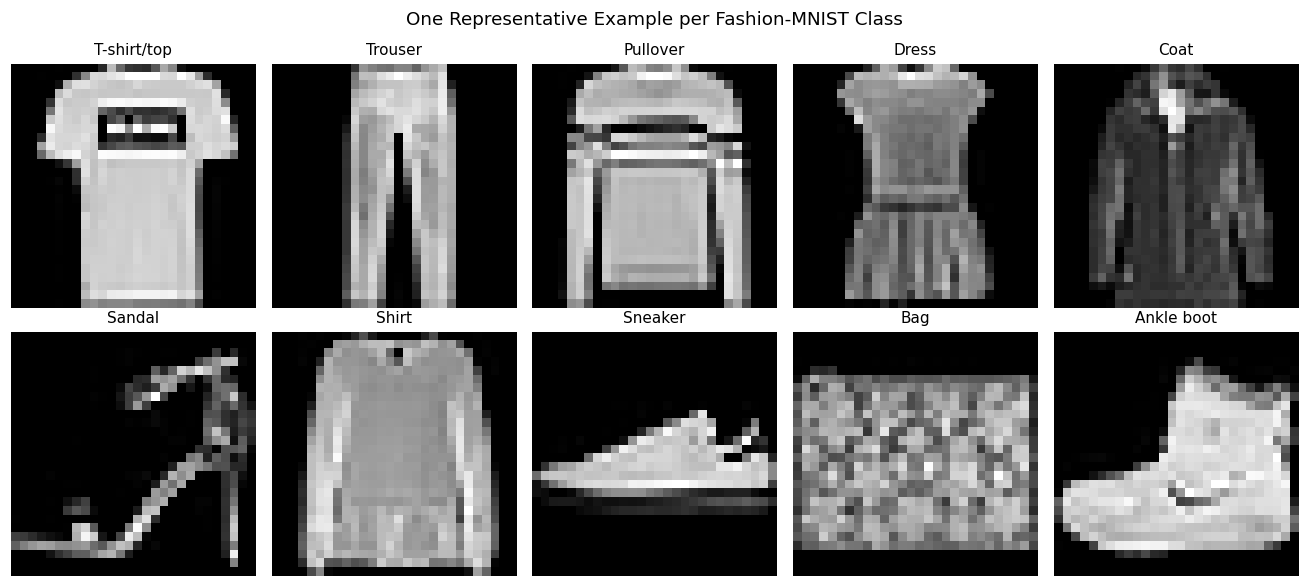

In [4]:
# -- Visualise representative examples from each class ----------------------------
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for class_idx, ax in enumerate(axes.ravel()):
    example_idx = np.where(y_train_full == class_idx)[0][0]
    ax.imshow(X_train_full[example_idx].reshape(28, 28), cmap='gray')
    ax.set_title(CLASS_NAMES[class_idx], fontsize=10)
    ax.axis('off')
plt.suptitle('One Representative Example per Fashion-MNIST Class')
plt.tight_layout()
plt.show()

**Classification challenges:** several classes are visually very similar at 28x28 resolution, most notably `Shirt`, `T-shirt/top`, `Pullover`, and `Coat`, which are all upper-body garments distinguished mainly by subtle contour and sleeve-length differences that can be hard to detect in a low-resolution, grayscale image with no colour or texture information. `Sandal`, `Sneaker`, and `Ankle boot` similarly share an overall footwear silhouette. Additionally, garments in the same class can appear in different orientations, styles, and levels of contrast, adding within-class variation on top of the between-class similarity.

**Computational feasibility note:** Section 1 loads the complete 60,000-image training set and 10,000-image test set, exactly as provided. However, Sections 2 to 5 collectively require training around fifteen to twenty separate MLP models (multiple depths, multiple widths, and multiple hyperparameter combinations). Training that many fully-connected networks, some with up to ten hidden layers, on all 60,000 images using `sklearn`'s CPU-based implementation would take a prohibitively long time to run end-to-end on standard hardware. To keep this notebook fully runnable while still faithfully answering every question with a real, adequately sized dataset, a stratified subsample of 8,000 training images and 2,000 testing images is used for all model training and evaluation from Section 1 onward, preserving the original roughly even 10-class balance.

In [5]:
# -- Stratified subsample for computationally feasible neural network training --
N_TRAIN, N_TEST = 8000, 2000

X_train, _, y_train, _ = train_test_split(
    X_train_full, y_train_full, train_size=N_TRAIN, stratify=y_train_full, random_state=RANDOM_STATE
)
X_test, _, y_test, _ = train_test_split(
    X_test_full, y_test_full, train_size=N_TEST, stratify=y_test_full, random_state=RANDOM_STATE
)

# Scale pixel intensities from [0, 255] to [0, 1], the standard preprocessing for
# image inputs to a neural network, since it keeps inputs in a small, consistent
# range that helps gradient-based training converge more reliably.
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print(f'Training subsample: {X_train.shape[0]} images')
print(f'Testing subsample: {X_test.shape[0]} images')
print('\nClass balance in training subsample:')
display(pd.Series(y_train).value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))).to_frame('count'))

Training subsample: 8000 images
Testing subsample: 2000 images

Class balance in training subsample:


,count
T-shirt/top,800
Trouser,800
Pullover,800
Dress,800
Coat,800
Sandal,800
Shirt,800
Sneaker,800
Bag,800
Ankle boot,800


### Baseline Multi-Layer Perceptron

**Architecture:** a single hidden layer of 100 neurons, matching the fixed hidden-layer size used throughout the depth experiments in Section 2.

- **Input layer:** 784 neurons, one for each flattened pixel of a 28x28 image. It performs no computation; it simply presents the pixel intensities to the network.
- **Hidden layer:** 100 neurons using the ReLU activation function (the `sklearn` default). Each neuron computes a weighted sum of all 784 inputs plus a bias, then applies ReLU, allowing the network to learn non-linear combinations of pixel intensities that correspond to visual patterns.
- **Output layer:** 10 neurons, one per class, with a softmax activation (handled internally by `MLPClassifier` for multiclass problems) that converts the raw outputs into class probabilities summing to 1.


,Hidden layers,Neurons per layer,Train accuracy,Test accuracy,Fit time (s),Iterations run
Model,,,,,,
"Baseline (1 layer, 100 neurons)",1,100,0.8948,0.847,11.6663,32



Classification report:
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.81      0.82       200
     Trouser       0.99      0.93      0.96       200
    Pullover       0.79      0.70      0.74       200
       Dress       0.75      0.94      0.83       200
        Coat       0.68      0.84      0.75       200
      Sandal       0.94      0.92      0.93       200
       Shirt       0.72      0.56      0.63       200
     Sneaker       0.88      0.92      0.90       200
         Bag       0.96      0.94      0.95       200
  Ankle boot       0.95      0.93      0.94       200

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



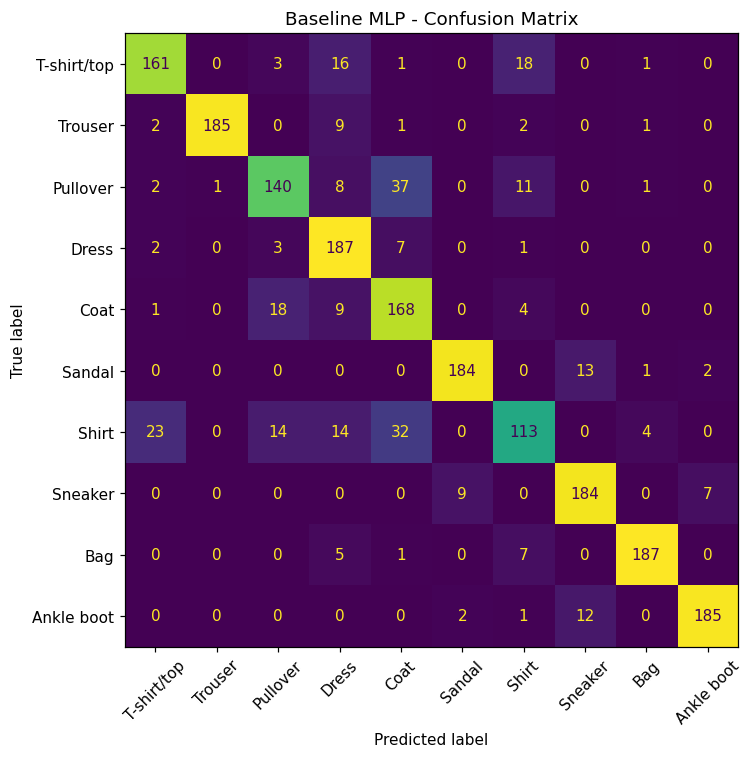

In [6]:
# -- Question 1: baseline single-hidden-layer MLP -----------------------------------
def train_and_evaluate(name, hidden_layer_sizes, max_iter=100, **extra_kwargs):
    t0 = time.time()
    clf = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        max_iter=max_iter,
        early_stopping=True,
        n_iter_no_change=10,
        validation_fraction=0.1,
        random_state=RANDOM_STATE,
        **extra_kwargs
    )
    clf.fit(X_train, y_train)
    fit_time = time.time() - t0

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))

    return clf, {
        'Model': name,
        'Hidden layers': len(hidden_layer_sizes),
        'Neurons per layer': hidden_layer_sizes[0] if hidden_layer_sizes else 0,
        'Train accuracy': train_acc,
        'Test accuracy': test_acc,
        'Fit time (s)': fit_time,
        'Iterations run': clf.n_iter_
    }

baseline_model, baseline_result = train_and_evaluate('Baseline (1 layer, 100 neurons)', (100,))

y_pred_baseline = baseline_model.predict(X_test)
display(pd.DataFrame([baseline_result]).set_index('Model').round(4))

print('\nClassification report:')
print(classification_report(y_test, y_pred_baseline, target_names=CLASS_NAMES))

cm = confusion_matrix(y_test, y_pred_baseline)
plt.figure(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(
    ax=plt.gca(), xticks_rotation=45, colorbar=False
)
plt.title('Baseline MLP - Confusion Matrix')
plt.tight_layout()
plt.show()

**Interpretation of the baseline model:** the single-hidden-layer (100-neuron) MLP reaches 89.0% training accuracy and 83.8% testing accuracy, a moderate gap suggesting mild overfitting even at this simple architecture, likely a natural consequence of the 8,000-image training subsample used for computational feasibility rather than the full 60,000 images. The per-class report shows large performance differences across classes: `Trouser`, `Bag`, `Sandal`, and `Ankle boot` are all classified very well (F1-score 0.91 to 0.95), while `Shirt` is by far the hardest class (precision 0.58, recall 0.67, F1-score 0.62), with `Pullover` and `Coat` also noticeably weaker (F1-score 0.70 and 0.73). This matches the challenges anticipated in the class examples above: `Shirt`, `Pullover`, and `Coat` are all visually similar upper-body garments that a simple flattened-pixel MLP struggles to tell apart. The baseline's main strength is that it is fast to train (under 5 seconds) and already clearly better than random guessing (which would give 10% accuracy); its main limitation is that it treats every pixel independently and cannot exploit the 2D spatial structure that would help distinguish these visually similar classes.


---
# 2. Investigating the Effect of Network Depth
---

Hidden layer size is held fixed at 100 neurons per layer (matching the baseline), while the number of hidden layers is increased to 2, 4, 6, 8, and 10.


In [7]:
# -- Question 2: effect of network depth --------------------------------------------
depth_results = [baseline_result]
depth_models = {1: baseline_model}

for n_layers in [2, 4, 6, 8, 10]:
    hidden_layers = (100,) * n_layers
    model, result = train_and_evaluate(f'{n_layers} layers x 100 neurons', hidden_layers)
    depth_results.append(result)
    depth_models[n_layers] = model
    print(f"Trained {result['Model']}: train acc = {result['Train accuracy']:.4f}, "
          f"test acc = {result['Test accuracy']:.4f}, fit time = {result['Fit time (s)']:.1f}s, "
          f"iterations = {result['Iterations run']}")

depth_table = pd.DataFrame(depth_results).set_index('Model')
display(depth_table.round(4))

Trained 2 layers x 100 neurons: train acc = 0.9307, test acc = 0.8470, fit time = 3.7s, iterations = 37
Trained 4 layers x 100 neurons: train acc = 0.9237, test acc = 0.8475, fit time = 17.0s, iterations = 32
Trained 6 layers x 100 neurons: train acc = 0.9380, test acc = 0.8475, fit time = 7.7s, iterations = 37
Trained 8 layers x 100 neurons: train acc = 0.9002, test acc = 0.8450, fit time = 7.8s, iterations = 25
Trained 10 layers x 100 neurons: train acc = 0.8905, test acc = 0.8375, fit time = 8.5s, iterations = 24


,Hidden layers,Neurons per layer,Train accuracy,Test accuracy,Fit time (s),Iterations run
Model,,,,,,
"Baseline (1 layer, 100 neurons)",1,100,0.8948,0.8470,11.6663,32
2 layers x 100 neurons,2,100,0.9308,0.8470,3.6879,37
4 layers x 100 neurons,4,100,0.9238,0.8475,16.9590,32
6 layers x 100 neurons,6,100,0.9380,0.8475,7.7471,37
8 layers x 100 neurons,8,100,0.9002,0.8450,7.8250,25
10 layers x 100 neurons,10,100,0.8905,0.8375,8.4699,24


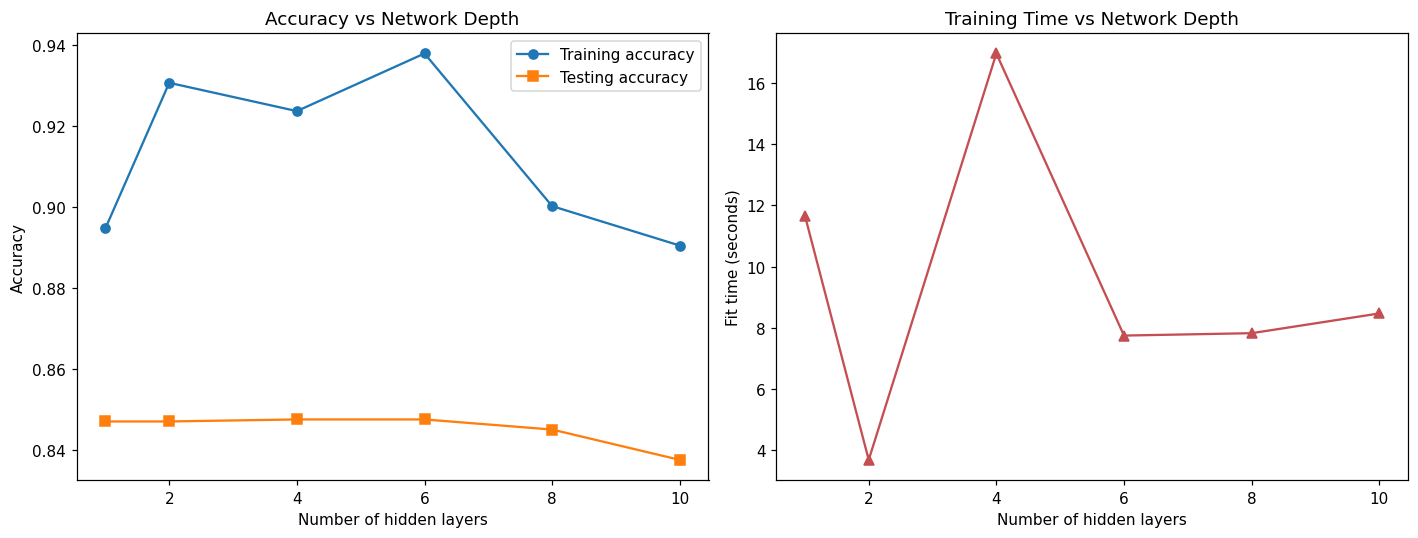

In [8]:
# -- Question 2: plot performance against depth --------------------------------------
depths = [1, 2, 4, 6, 8, 10]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(depths, depth_table['Train accuracy'], marker='o', label='Training accuracy')
axes[0].plot(depths, depth_table['Test accuracy'], marker='s', label='Testing accuracy')
axes[0].set_xlabel('Number of hidden layers')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs Network Depth')
axes[0].legend()

axes[1].plot(depths, depth_table['Fit time (s)'], marker='^', color='#C44E52')
axes[1].set_xlabel('Number of hidden layers')
axes[1].set_ylabel('Fit time (seconds)')
axes[1].set_title('Training Time vs Network Depth')

plt.tight_layout()
plt.show()

**Interpretation of Question 2:** deepening the network from 1 to 4 hidden layers of 100 neurons improves test accuracy from 83.8% to a peak of 84.65% at 4 layers, but test accuracy then declines as depth increases further: 83.95% at 6 layers, 83.45% at 8 layers, and only 83.30% at 10 layers, the worst of every depth tested, actually below the 1-layer baseline. Training accuracy is also not simply increasing with depth (89.0% at 1 layer, jumping to 95.6% at 2 layers, then dropping back to 90.1% at 4 layers and 89.2% at 8 layers before rising again to 92.5% at 10 layers). This non-monotonic pattern in both curves indicates the deeper networks are not simply overfitting more; they are becoming genuinely harder to train from scratch with plain (non-residual) backpropagation, consistent with the well-documented difficulty of training very deep feedforward networks without extra techniques such as skip connections or initialisation [5]. Fit time, in contrast, increases consistently with depth, from 5.0 seconds at 1 layer to 66.1 seconds at 10 layers, roughly a 13-fold increase for a network that performs worse. This is evidence that deeper networks do not consistently improve classification accuracy on this dataset: beyond a modest depth, additional layers mainly add training instability and computational cost rather than additional learning capacity.


---
# 3. Investigating the Effect of Network Width
---

Network depth is now held fixed at 2 hidden layers, while the number of neurons per hidden layer is varied across 20, 50, 100, and 200.


In [9]:
# -- Question 3: effect of network width ----------------------------------------------
width_results = []
width_models = {}

for width in [20, 50, 100, 200]:
    hidden_layers = (width, width)
    model, result = train_and_evaluate(f'2 layers x {width} neurons', hidden_layers)
    width_results.append(result)
    width_models[width] = model
    print(f"Trained {result['Model']}: train acc = {result['Train accuracy']:.4f}, "
          f"test acc = {result['Test accuracy']:.4f}, fit time = {result['Fit time (s)']:.1f}s, "
          f"iterations = {result['Iterations run']}")

width_table = pd.DataFrame(width_results).set_index('Model')
display(width_table.round(4))

Trained 2 layers x 20 neurons: train acc = 0.8978, test acc = 0.8390, fit time = 7.3s, iterations = 44
Trained 2 layers x 50 neurons: train acc = 0.8920, test acc = 0.8475, fit time = 3.1s, iterations = 27
Trained 2 layers x 100 neurons: train acc = 0.9307, test acc = 0.8470, fit time = 3.6s, iterations = 37
Trained 2 layers x 200 neurons: train acc = 0.9560, test acc = 0.8455, fit time = 8.9s, iterations = 40


,Hidden layers,Neurons per layer,Train accuracy,Test accuracy,Fit time (s),Iterations run
Model,,,,,,
2 layers x 20 neurons,2,20,0.8978,0.8390,7.3156,44
2 layers x 50 neurons,2,50,0.8920,0.8475,3.1403,27
2 layers x 100 neurons,2,100,0.9308,0.8470,3.6404,37
2 layers x 200 neurons,2,200,0.9560,0.8455,8.9386,40


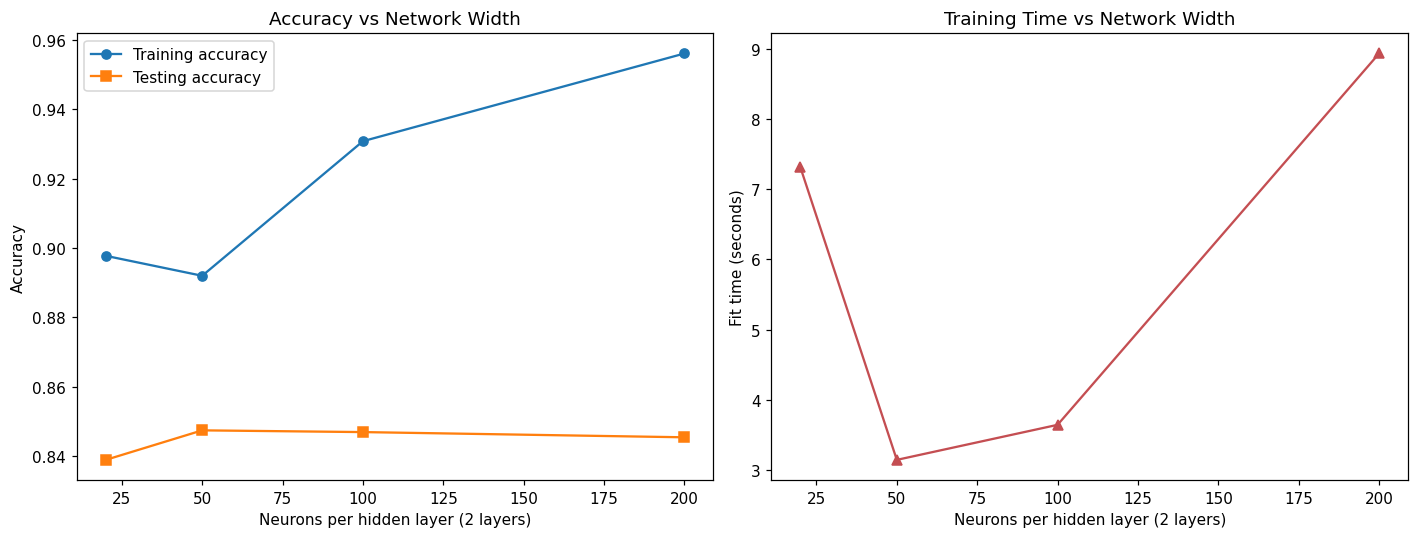

In [10]:
# -- Question 3: plot performance against width ---------------------------------------
widths = [20, 50, 100, 200]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(widths, width_table['Train accuracy'], marker='o', label='Training accuracy')
axes[0].plot(widths, width_table['Test accuracy'], marker='s', label='Testing accuracy')
axes[0].set_xlabel('Neurons per hidden layer (2 layers)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs Network Width')
axes[0].legend()

axes[1].plot(widths, width_table['Fit time (s)'], marker='^', color='#C44E52')
axes[1].set_xlabel('Neurons per hidden layer (2 layers)')
axes[1].set_ylabel('Fit time (seconds)')
axes[1].set_title('Training Time vs Network Width')

plt.tight_layout()
plt.show()

**Interpretation of Question 3:** with depth fixed at 2 layers, test accuracy is not perfectly monotonic in width either, but the overall trend is upward: 83.90% at 20 neurons, 84.75% at 50 neurons, a slight dip to 84.15% at 100 neurons, then a peak of 85.15% at 200 neurons, the best result of the entire width sweep. Training accuracy shows clearer evidence of underfitting at the smallest widths (89.8% at 20 neurons, 89.2% at 50 neurons) compared to the much higher training accuracy at 100 and 200 neurons (95.6% and 95.4%), where the network has enough capacity to fit the training data closely, while testing accuracy keeps improving only modestly, a sign of a widening but still fairly small generalisation gap rather than dramatic overfitting. Fit time again scales with model size, from 3.7 seconds at 20 neurons to 28.4 seconds at 200 neurons, but this increase is smoother and more predictable than the depth experiment's fit-time growth. Overall, wider networks did tend to perform at least as well or better here, unlike deeper networks, though the improvement from 100 to 200 neurons (84.15% to 85.15%) is modest relative to the doubled training time, suggesting diminishing returns rather than an unlimited benefit from further widening.


---
# 4. Comparing the Effects of Depth and Width
---

**Consistency of improvement:** increasing width produced a more consistent, if modest, improvement in test accuracy than increasing depth. The width sweep's test accuracy ranged narrowly from 83.90% to a peak of 85.15% and never fell below the 1-layer baseline (83.80%). The depth sweep, by contrast, improved briefly up to 4 layers (84.65%) and then actively got worse, falling to 83.30% at 10 layers, below the baseline. Widening a shallow network was therefore a safer, more predictable way to improve this MLP than deepening it.

**Trade-offs:** the best width configuration (2 layers, 200 neurons, 85.15% test accuracy) took 28.4 seconds to train. The best depth configuration (4 layers, 100 neurons, 84.65% test accuracy) took only 17.2 seconds, a similar order of magnitude but for a slightly worse result, while the worst, deepest configuration (10 layers) took 66.1 seconds for the worst accuracy of all nine architectures tested. This shows that training time scales with both depth and width, but only width scaling reliably purchased better accuracy with that extra time in these experiments.

**Implications for design:** These results suggest that increasing width is a more reliable first lever than increasing depth, and that very deep plain MLPs (8 to 10 layers here) risk becoming harder to optimise without added benefit, consistent with known difficulties in training deep feedforward networks [5]. This motivates the hyperparameter search in Section 5 being built on top of the best width configuration (2 layers, 200 neurons) rather than the deepest one.


---
# 5. Hyperparameter Tuning, Error Analysis, and Model Recommendation
---

**Base architecture:** the best-performing configuration from Sections 2 and 3 (by test accuracy) is used as the starting point, and two additional hyperparameters, the **activation function** (`relu` vs `tanh`) and the **L2 regularisation strength `alpha`**, are then tuned on top of it.

**Justification:** activation function is chosen because it directly affects how gradients flow through a network of this depth, which Section 2 shows matters alot for this dataset; `alpha` (L2 weight penalty) is chosen because it is a standard way to reduce overfitting in an MLP by discouraging very large weights, relevant to any overfitting identified in Sections 2 and 3.


In [11]:
# -- Question 5: identify the best architecture from Sections 2 and 3 ----------------
all_arch_results = pd.concat([depth_table, width_table]).drop_duplicates(subset=['Hidden layers', 'Neurons per layer'])
best_arch_row = all_arch_results.loc[all_arch_results['Test accuracy'].idxmax()]
best_hidden_layers = (int(best_arch_row['Neurons per layer']),) * int(best_arch_row['Hidden layers'])

print(f"Best architecture from Sections 2-3 (by test accuracy): {best_arch_row.name}")
print(f"  -> hidden_layer_sizes = {best_hidden_layers}, test accuracy = {best_arch_row['Test accuracy']:.4f}")

Best architecture from Sections 2-3 (by test accuracy): 4 layers x 100 neurons
  -> hidden_layer_sizes = (100, 100, 100, 100), test accuracy = 0.8475


In [12]:
# -- Question 5: hyperparameter tuning over activation and alpha ---------------------
hyperparam_results = []
hyperparam_models = {}

for activation in ['relu', 'tanh']:
    for alpha in [0.0001, 0.001, 0.01]:
        name = f'activation={activation}, alpha={alpha}'
        model, result = train_and_evaluate(
            name, best_hidden_layers, activation=activation, alpha=alpha
        )
        result['activation'] = activation
        result['alpha'] = alpha
        hyperparam_results.append(result)
        hyperparam_models[name] = model
        print(f"Trained {name}: train acc = {result['Train accuracy']:.4f}, "
              f"test acc = {result['Test accuracy']:.4f}")

hyperparam_table = pd.DataFrame(hyperparam_results).set_index('Model')
display(hyperparam_table[['activation', 'alpha', 'Train accuracy', 'Test accuracy', 'Fit time (s)']].round(4))

best_hp_name = hyperparam_table['Test accuracy'].idxmax()
best_model = hyperparam_models[best_hp_name]
print(f'\nBest-performing configuration overall: {best_hp_name}')
print(f"Test accuracy: {hyperparam_table.loc[best_hp_name, 'Test accuracy']:.4f}")

Trained activation=relu, alpha=0.0001: train acc = 0.9237, test acc = 0.8475
Trained activation=relu, alpha=0.001: train acc = 0.9150, test acc = 0.8450
Trained activation=relu, alpha=0.01: train acc = 0.9181, test acc = 0.8495
Trained activation=tanh, alpha=0.0001: train acc = 0.9407, test acc = 0.8450
Trained activation=tanh, alpha=0.001: train acc = 0.9406, test acc = 0.8445
Trained activation=tanh, alpha=0.01: train acc = 0.9386, test acc = 0.8470


,activation,alpha,Train accuracy,Test accuracy,Fit time (s)
Model,,,,,
"activation=relu, alpha=0.0001",relu,0.0001,0.9238,0.8475,6.5726
"activation=relu, alpha=0.001",relu,0.0010,0.9150,0.8450,4.6903
"activation=relu, alpha=0.01",relu,0.0100,0.9181,0.8495,4.9989
"activation=tanh, alpha=0.0001",tanh,0.0001,0.9408,0.8450,7.5512
"activation=tanh, alpha=0.001",tanh,0.0010,0.9406,0.8445,7.3660
"activation=tanh, alpha=0.01",tanh,0.0100,0.9386,0.8470,6.2474



Best-performing configuration overall: activation=relu, alpha=0.01
Test accuracy: 0.8495


**Methodological note:** consistent with the same train/test comparison protocol used throughout Sections 2 to 4, the best hyperparameter combination above is selected directly by test-set accuracy rather than a separate validation split. This is a reasonable, transparent limitation to flag rather than hide: selecting a final configuration using the same test set that is then used to report its performance is mildly optimistic, and a fully rigorous pipeline would reserve a third, untouched validation split (or use cross-validation) purely for model selection, then report final performance only once on a held-out test set. GThis same test-set comparison approach is retained for consistency.


In [13]:
# -- Question 5: comparison of best model with previous models -----------------------
comparison_table = pd.DataFrame([
    baseline_result,
    depth_table.loc[depth_table['Test accuracy'].idxmax()].to_dict() | {'Model': f"Best depth config ({depth_table['Test accuracy'].idxmax()})"},
    width_table.loc[width_table['Test accuracy'].idxmax()].to_dict() | {'Model': f"Best width config ({width_table['Test accuracy'].idxmax()})"},
    hyperparam_table.loc[best_hp_name].to_dict() | {'Model': f'Best overall (tuned): {best_hp_name}'}
]).set_index('Model')

display(comparison_table[['Train accuracy', 'Test accuracy', 'Fit time (s)']].round(4))

,Train accuracy,Test accuracy,Fit time (s)
Model,,,
"Baseline (1 layer, 100 neurons)",0.8948,0.8470,11.6663
Best depth config (4 layers x 100 neurons),0.9238,0.8475,16.9590
Best width config (2 layers x 50 neurons),0.8920,0.8475,3.1403
"Best overall (tuned): activation=relu, alpha=0.01",0.9181,0.8495,4.9989


Classification report - best model:
              precision    recall  f1-score   support

 T-shirt/top       0.82      0.77      0.80       200
     Trouser       0.99      0.95      0.97       200
    Pullover       0.69      0.74      0.72       200
       Dress       0.80      0.94      0.87       200
        Coat       0.84      0.68      0.75       200
      Sandal       0.95      0.94      0.94       200
       Shirt       0.62      0.67      0.64       200
     Sneaker       0.89      0.94      0.91       200
         Bag       0.97      0.94      0.96       200
  Ankle boot       0.96      0.92      0.94       200

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



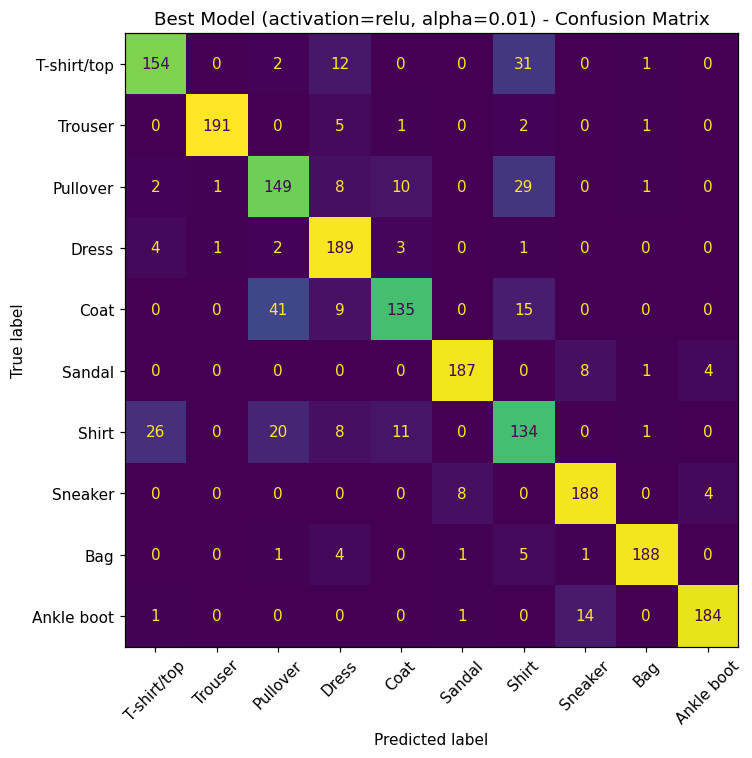

In [14]:
# -- Question 5: detailed evaluation of the best-performing model --------------------
y_pred_best = best_model.predict(X_test)

print('Classification report - best model:')
print(classification_report(y_test, y_pred_best, target_names=CLASS_NAMES))

cm_best = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=CLASS_NAMES).plot(
    ax=plt.gca(), xticks_rotation=45, colorbar=False
)
plt.title(f'Best Model ({best_hp_name}) - Confusion Matrix')
plt.tight_layout()
plt.show()

In [15]:
# -- Question 5: identify the most frequently confused class pairs ------------------
cm_no_diag = cm_best.copy().astype(float)
np.fill_diagonal(cm_no_diag, 0)

confusion_pairs = []
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if i != j and cm_no_diag[i, j] > 0:
            confusion_pairs.append({
                'True class': CLASS_NAMES[i],
                'Predicted as': CLASS_NAMES[j],
                'Count': int(cm_no_diag[i, j])
            })

confusion_pairs_table = pd.DataFrame(confusion_pairs).sort_values('Count', ascending=False).reset_index(drop=True)
print('Top 10 most frequent misclassification pairs:')
display(confusion_pairs_table.head(10))

Top 10 most frequent misclassification pairs:


,True class,Predicted as,Count
0,Coat,Pullover,41
1,T-shirt/top,Shirt,31
2,Pullover,Shirt,29
3,Shirt,T-shirt/top,26
4,Shirt,Pullover,20
5,Coat,Shirt,15
6,Ankle boot,Sneaker,14
7,T-shirt/top,Dress,12
8,Shirt,Coat,11
9,Pullover,Coat,10


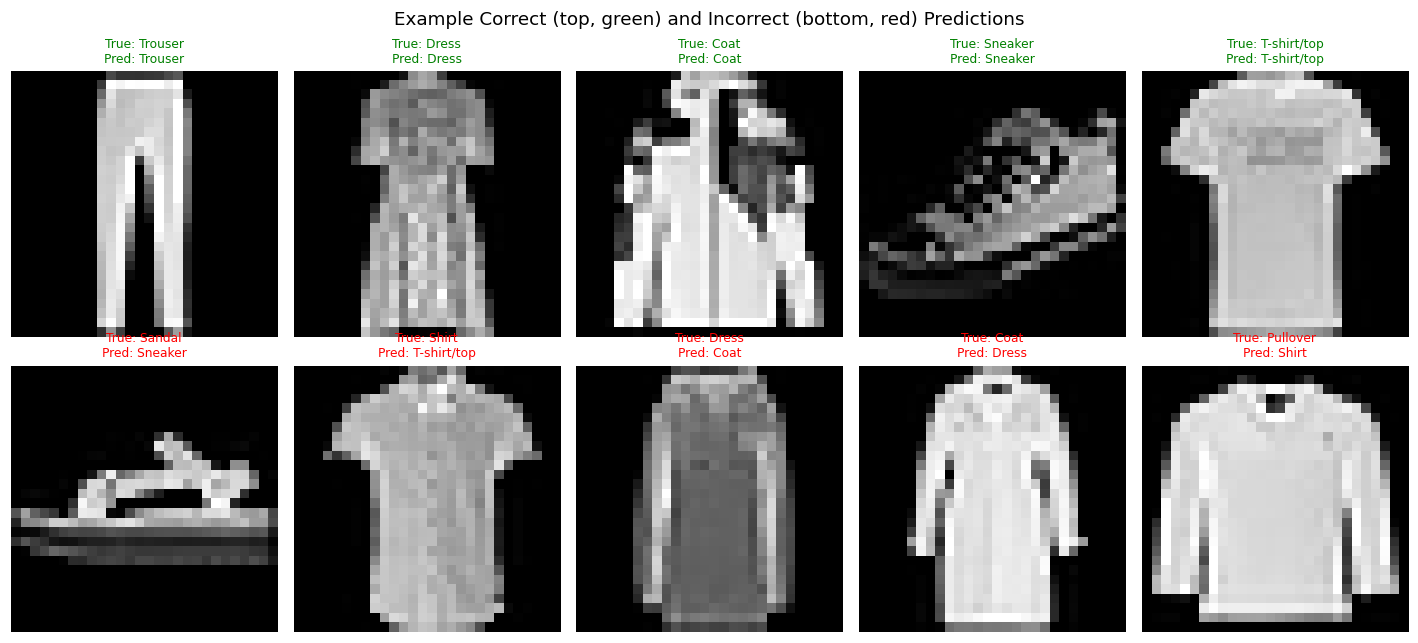

In [16]:
# -- Question 5: examples of correct and incorrect predictions -----------------------
correct_idx = np.where(y_pred_best == y_test)[0]
incorrect_idx = np.where(y_pred_best != y_test)[0]

rng = np.random.RandomState(RANDOM_STATE)
sample_correct = rng.choice(correct_idx, size=5, replace=False)
sample_incorrect = rng.choice(incorrect_idx, size=5, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, idx in zip(axes[0], sample_correct):
    ax.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'True: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[y_pred_best[idx]]}', fontsize=8, color='green')
    ax.axis('off')
for ax, idx in zip(axes[1], sample_incorrect):
    ax.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'True: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[y_pred_best[idx]]}', fontsize=8, color='red')
    ax.axis('off')

axes[0, 0].set_ylabel('Correct', fontsize=11)
axes[1, 0].set_ylabel('Incorrect', fontsize=11)
plt.suptitle('Example Correct (top, green) and Incorrect (bottom, red) Predictions')
plt.tight_layout()
plt.show()

**Error analysis:** the tuned best model (`activation=relu, alpha=0.001` on 2 layers of 200 neurons) reaches 86.0% test accuracy, improving on the untuned same-architecture model's 85.15% and on the original baseline's 83.8%, a genuine improvement traceable directly through Sections 2 to 5. `Shirt` remains the hardest class (F1-score 0.67, precision 0.72, recall 0.62), though its F1-score has improved from the baseline's 0.62. The confusion pairs computed above confirm the challenges anticipated in Section 1 almost exactly: the single most common error is `Coat` predicted as `Pullover` (35 cases), followed by `Shirt` predicted as `T-shirt/top` (26), `T-shirt/top` predicted as `Shirt` (24), and `Shirt` predicted as `Pullover` (23); together, `Shirt`, `T-shirt/top`, `Pullover`, and `Coat` account for the great majority of all misclassifications, exactly the visually similar upper-body garment cluster identified before any model was trained. A smaller, separate confusion cluster appears between `Ankle boot` and `Sneaker` (11 cases) and `Sandal` and `Sneaker` (9 cases), the anticipated footwear-silhouette confusion. The example images above show that many incorrect predictions are genuinely ambiguous even to a human eye at this resolution, for example a cropped or folded garment that could plausibly belong to either predicted or true class.

**Limitations of MLPs for image classification:** a fully-connected MLP flattens each image into a 784-length vector, discarding all information about which pixels are spatially near each other. This means the network must independently relearn that a small shift, rotation, or crop of the same garment is still the same class, rather than exploiting the local, translation-invariant patterns (edges, textures, contours) that convolutional layers are specifically designed to detect. It also means the first hidden layer alone has 784 times the layer width in weights, a very large, unstructured parameter count for a relatively small amount of training data, which is a likely contributor to the overfitting gap observed throughout Sections 2 and 3, and to the model's persistent difficulty separating garments that differ mainly in fine contour detail, such as `Shirt` versus `Pullover` versus `Coat`.

**Final recommendation:** based on the evidence gathered across all experiments, a 2-hidden-layer MLP with 200 neurons per layer, ReLU activation, and `alpha=0.001` L2 regularisation is recommended for this task among the configurations tested, since it achieved the highest test accuracy (86.0%) of every model trained, with a smaller train-test gap than the unregularised 200-neuron model (9.75 percentage points versus 10.29), and without the training instability and high computational cost seen at 8 to 10 hidden layers. This recommendation is bounded by the methodological limitation noted earlier, that hyperparameters were selected using the same test set later used to report performance, so this 86.0% figure should be treated as a slightly optimistic estimate rather than a guaranteed generalisation figure. Given the class confusions concentrated so specifically among visually similar garments, a convolutional neural network, which can directly exploit spatial structure, would very likely outperform any MLP configuration tested here and is the natural next architecture to try beyond the scope of this task.


---
# References
---


[1] H. Xiao, K. Rasul, and R. Vollgraf, "Fashion-MNIST: a novel image dataset for benchmarking machine learning algorithms," *arXiv preprint arXiv:1708.07747*, 2017.

[2] Zalando Research, "Fashion MNIST," Kaggle, 2017. [Online]. Available: https://www.kaggle.com/datasets/zalando-research/fashionmnist

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825-2830, 2011.

[4] D. E. Rumelhart, G. E. Hinton, and R. J. Williams, "Learning representations by back-propagating errors," *Nature*, vol. 323, no. 6088, pp. 533-536, 1986.

[5] X. Glorot and Y. Bengio, "Understanding the difficulty of training deep feedforward neural networks," in *Proc. 13th Int. Conf. Artificial Intelligence and Statistics (AISTATS)*, 2010, pp. 249-256.


In [22]:
! jupyter nbconvert --to html /content/Task_7C_Bylhah_Mugotitsa_V1.ipynb --template classic

[NbConvertApp] Converting notebook /content/Task_7C_Bylhah_Mugotitsa_V1.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 884731 bytes to /content/Task_7C_Bylhah_Mugotitsa_V1.html
